In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
from gensim.parsing.preprocessing import remove_stopwords
from sklearn.decomposition import PCA

In [2]:
tw = pd.read_csv("twitter_dataset.csv")
tw.head()

,Tweet_ID,Username,Text,Retweets,Likes,Timestamp
0,1,julie81,Party least receive say or single. Prevent pre...,2,25,2023-01-30 11:00:51
1,2,richardhester,Hotel still Congress may member staff. Media d...,35,29,2023-01-02 22:45:58
2,3,williamsjoseph,Nice be her debate industry that year. Film wh...,51,25,2023-01-18 11:25:19
3,4,danielsmary,Laugh explain situation career occur serious. ...,37,18,2023-04-10 22:06:29
4,5,carlwarren,Involve sense former often approach government...,27,80,2023-01-24 07:12:21


In [3]:
tok = [simple_preprocess(remove_stopwords(t.lower())) for t in tw.Text]
wv = Word2Vec(tok,vector_size=100,window=5,min_count=2,sg=0,epochs=30).wv

In [5]:
w = wv.index_to_key[:3]
print(w, "| vocabulary:", len(wv))
print(wv.most_similar(w[0], topn=5))                                                 # nearest words
print(wv.similarity(w[0], w[1]))                                                     # similarity of two words (-1..1)
print(wv[w[0]][:5])                                                                  # the vector of a word

['hard', 'tax', 'add'] | vocabulary: 969
[('page', 0.32063528895378113), ('cut', 0.3194761574268341), ('community', 0.2803193926811218), ('least', 0.2611754834651947), ('ago', 0.2551456391811371)]
0.030816639
[ 1.4075722   0.7196227   0.38380054  0.08996472 -0.7430849 ]


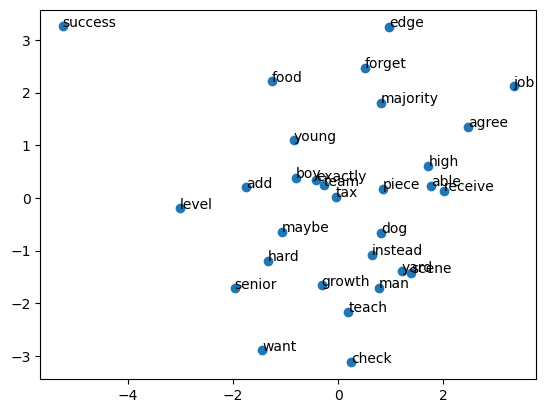

In [6]:
words = wv.index_to_key[:30]
xy = PCA(2).fit_transform(wv[words])                   # 2-D map of the words
plt.scatter(*xy.T)
[plt.annotate(a, p) for a, p in zip(words, xy)]
plt.show()      # close points = related words